# Exploratory Data Analysis



| File | Kaggle source | Role |
|---|---|---|
| `malicious_phish.csv` | *Malicious URLs dataset* (sid321axn) | Primary dataset, same as the paper (651,191 URLs, 4 classes) |
| `balanced_urls.csv` | *Benign and Malicious URLs* (samahsadiq) | Secondary, binary and balanced (already in our deck) |

In [1]:
import re, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 90)

# Works in Colab (after upload), locally, or in the sandbox
for d in ["/mnt/user-data/uploads", "/content", "."]:
    if os.path.exists(os.path.join(d, "malicious_phish.csv")):
        DATA = d; break
print("Data folder:", DATA)
phish = pd.read_csv(f"{DATA}/malicious_phish.csv")
bal   = pd.read_csv(f"{DATA}/balanced_urls.csv")

Data folder: /mnt/user-data/uploads


## 1. Size and structure

In [2]:
summary = pd.DataFrame({
    "rows":[len(phish), len(bal)],
    "columns":[phish.shape[1], bal.shape[1]],
    "column names":[list(phish.columns), list(bal.columns)],
    "memory (MB)":[round(phish.memory_usage(deep=True).sum()/1e6,1), round(bal.memory_usage(deep=True).sum()/1e6,1)],
}, index=["malicious_phish.csv","balanced_urls.csv"])
summary

,rows,columns,column names,memory (MB)
malicious_phish.csv,651191,2,"[url, type]",107.6
balanced_urls.csv,632508,3,"[url, label, result]",110.7


In [3]:
print("malicious_phish.csv"); display(phish.dtypes.to_frame("dtype").T); display(phish.sample(8, random_state=7))
print("balanced_urls.csv");   display(bal.dtypes.to_frame("dtype").T);   display(bal.sample(8, random_state=7))

malicious_phish.csv


,url,type
dtype,str,str


,url,type
651162,www.armchairempire.com/Reviews/XBox/call-cthulhu-dark-corners-earth.htm,phishing
82135,bassflava.com/mp3/Bouger+Bouger+-+Feat+Num%C3%A9ro%23-song-810141.html,benign
397711,http://www.zibae.ir/index.php?option=com_content&view=category&layout=blog&id=16&Itemi...,defacement
61149,sportsyakima.com/2010/01/prep-basketball-roundup-pirates-rally-to-stop-ml-in-ot/,benign
603789,tech.groups.yahoo.com/group/Goatads/,phishing
38486,danharmonsucks.com/board/showthread.php?t=18,benign
343489,infoplease.com/ipsa/A0104163.html,benign
467154,sports.yahoo.com/mma/news?slug=ki-ufcearly050810,benign


balanced_urls.csv


,url,label,result
dtype,str,str,int64


,url,label,result
536701,http://www.wingert-sonnenschutz.de/index.php?option=com_content&view=article&id=54&Ite...,malicious,1
82439,https://www.uk.ratemyteachers.com/the-henrietta-barnett-school/22167-s,benign,0
358496,http://dircom.org/wells/c63228a590b7879e2cfbddad38c17e6c/,malicious,1
121379,https://www.birminghamcyclist.com/,benign,0
331759,http://christtemplecogic.org/wpinclude/aim,malicious,1
130227,https://www.cdbaby.com/cd/jimmartinmusic,benign,0
217667,https://www.metrolyrics.com/imparfait-lyrics-belanger-daniel.html,benign,0
10094,https://www.en.wikipedia.org/wiki/Star_Trek,benign,0


Both files hold raw URL strings and a label; there are no pre-computed features, so every feature must be engineered from the string (as in the paper's Table I).
`malicious_phish.csv` has a 4-class label (`type`). `balanced_urls.csv` has a text label plus a 0/1 `result` column.

## 2. Data quality

In [4]:
def quality(df, name, url="url"):
    s = df[url]
    return pd.Series({
        "rows": len(df),
        "null cells": int(df.isna().sum().sum()),
        "empty / whitespace-only URLs": int((s.str.strip()=="").sum()),
        "URLs with leading/trailing spaces": int((s!=s.str.strip()).sum()),
        "fully duplicated rows": int(df.duplicated().sum()),
        "duplicated URL strings": int(s.duplicated().sum()),
        "unique URLs": int(s.nunique()),
        "URLs with non-ASCII chars": int((~s.str.match(r'^[\x00-\x7f]*$')).sum()),
        "min length": int(s.str.len().min()),
        "max length": int(s.str.len().max()),
    }, name=name)
display(pd.concat([quality(phish,"malicious_phish"), quality(bal,"balanced_urls")], axis=1))

,malicious_phish,balanced_urls
rows,651191,632508
null cells,0,0
empty / whitespace-only URLs,0,0
URLs with leading/trailing spaces,7,5
fully duplicated rows,10066,0
duplicated URL strings,10072,0
unique URLs,641119,632508
URLs with non-ASCII chars,921,809
min length,1,1
max length,2175,2314


**Nulls:** none in either file, matching the paper's statement that the data has no null or empty cells.
**Duplicates:** `malicious_phish.csv` contains about 10k duplicated rows (about 1.5%). The paper does not mention this. Duplicates that land on both sides of a train/test split inflate test accuracy, so they matter. Next: do any duplicated URLs carry *different* labels?

In [5]:
dup_rows = phish[phish.duplicated(keep=False)]
print("Rows involved in exact duplication:", len(dup_rows))
print("\nLabel mix of the duplicated rows:"); print(phish[phish.duplicated()].type.value_counts())

nlab = phish.groupby("url").type.nunique()
conflict = nlab[nlab>1].index
print(f"\nURLs appearing with more than one label: {len(conflict)}")
display(phish[phish.url.isin(conflict)].sort_values("url").head(14))

Rows involved in exact duplication: 12267

Label mix of the duplicated rows:


type
malware       8875
defacement    1149
benign          23
phishing        19
Name: count, dtype: int64



URLs appearing with more than one label: 6


,url,type
328665,ebookstore.sony.com/reader/,benign
616942,ebookstore.sony.com/reader/,phishing
259609,en.wikipedia.org/wiki/Desktop_publishing,benign
616832,en.wikipedia.org/wiki/Desktop_publishing,phishing
213051,en.wikipedia.org/wiki/E-book,benign
616866,en.wikipedia.org/wiki/E-book,phishing
275788,groups.yahoo.com/group/Band-in-a-Box/,benign
625973,groups.yahoo.com/group/Band-in-a-Box/,phishing
181226,memory.loc.gov/ammem/ccmphtml/colahome.html,benign
609889,memory.loc.gov/ammem/ccmphtml/colahome.html,phishing


In [6]:
# Same checks on the secondary file, plus overlap between the two datasets
print("balanced_urls duplicated URLs:", bal.url.duplicated().sum())
print("label vs result consistent:", (bal.groupby("label").result.nunique()==1).all())

def norm(u): return re.sub(r'^https?://','',u.lower()).rstrip('/')
set_p, set_b = set(phish.url.map(norm)), set(bal.url.map(norm))
print(f"\nOverlap after stripping scheme/trailing slash: {len(set_p&set_b):,} URLs "
      f"({len(set_p&set_b)/len(set_b):.1%} of balanced_urls, {len(set_p&set_b)/len(set_p):.1%} of malicious_phish)")

balanced_urls duplicated URLs: 0
label vs result consistent: True



Overlap after stripping scheme/trailing slash: 210,817 URLs (33.8% of balanced_urls, 33.3% of malicious_phish)


## 3. Class distribution

,our count,paper (Fig. 7),match,share %
type,,,,
benign,428103,428103,True,65.7
defacement,96457,96457,True,14.8
phishing,94111,94111,True,14.5
malware,32520,32520,True,5.0


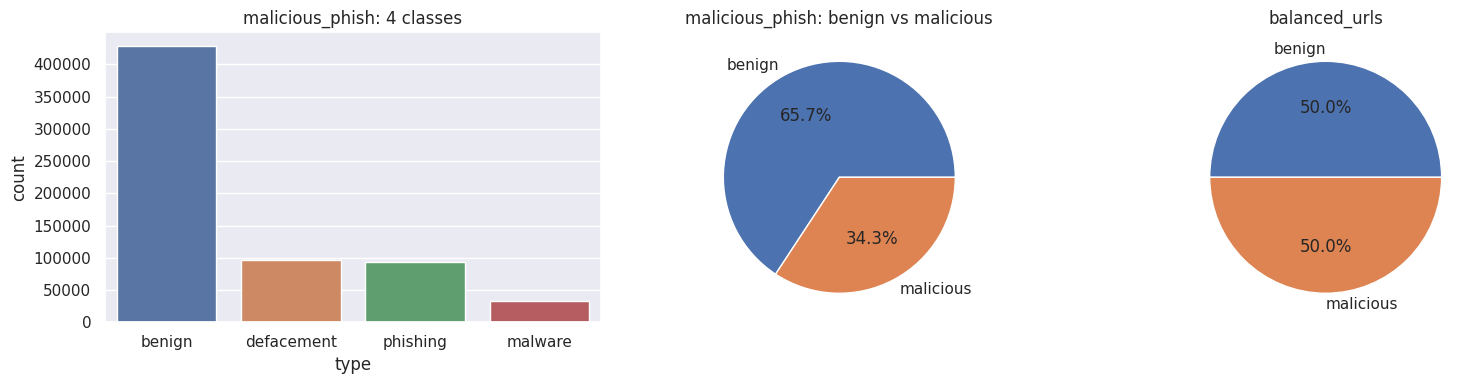

In [7]:
order = ["benign","defacement","phishing","malware"]
paper = pd.Series({"benign":428103,"defacement":96457,"phishing":94111,"malware":32520})
dist = phish.type.value_counts().reindex(order).to_frame("our count")
dist["paper (Fig. 7)"] = paper
dist["match"] = dist["our count"]==dist["paper (Fig. 7)"]
dist["share %"] = (dist["our count"]/len(phish)*100).round(1)
display(dist)

fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.countplot(data=phish, x="type", order=order, ax=ax[0], palette="deep"); ax[0].set_title("malicious_phish: 4 classes")
phish.assign(group=np.where(phish.type=="benign","benign","malicious")).group.value_counts().plot.pie(autopct="%.1f%%", ax=ax[1], ylabel="")
ax[1].set_title("malicious_phish: benign vs malicious")
bal.label.value_counts().plot.pie(autopct="%.1f%%", ax=ax[2], ylabel=""); ax[2].set_title("balanced_urls")
plt.tight_layout(); plt.show()

Class counts match the paper's Fig. 7 exactly, so `malicious_phish.csv` is the dataset the authors used. It is **imbalanced** (benign is about 66%, malware about 5%). That explains the paper's weaker recall on malware. `balanced_urls.csv` is a perfect 50/50 binary split.

## 4. Lexical feature extraction (paper Table I)

In [8]:
IP_RE  = re.compile(r'^(\d{1,3}\.){3}\d{1,3}(:\d+)?$')
SHORT  = r'bit\.ly|goo\.gl|t\.co|tinyurl|ow\.ly|is\.gd|buff\.ly|adf\.ly|bit\.do|cutt\.ly|rb\.gy|shorte\.st|tr\.im|x\.co|prettylinkpro|qr\.net|1url|tweez\.me|v\.gd|u\.to|j\.mp'

def features(df, url="url"):
    u = df[url]
    rest = u.str.replace(r'^[A-Za-z][A-Za-z0-9+.-]*://', '', regex=True)
    host = rest.str.split(r'[/?#]', n=1, regex=True).str[0]
    path = pd.Series([r[len(h):] for r,h in zip(rest,host)], index=df.index)
    F = pd.DataFrame(index=df.index)
    F["has_scheme"]    = u.str.match(r'^[A-Za-z][A-Za-z0-9+.-]*://').astype(int)
    F["use_of_ip"]     = host.map(lambda h: bool(IP_RE.match(h))).astype(int)
    F["url_length"]    = u.str.len()
    F["hostname_length"]= host.str.len()
    F["path_length"]   = path.str.len()
    F["fd_length"]     = path.str.split('/').str[1].fillna('').str.split(r'[?#]',regex=True).str[0].str.len()
    F["tld_length"]    = host.str.rsplit('.', n=1).str[-1].where(host.str.contains(r'\.'), '').str.len()
    F["count_dot"]     = u.str.count(r'\.')
    F["count_www"]     = u.str.count('www')
    F["count_at"]      = u.str.count('@')
    F["count_dir"]     = path.str.count('/')
    F["count_embed_domain"] = rest.str.count('//')
    F["count_http"]    = u.str.count('http')
    F["count_percent"] = u.str.count('%')
    F["count_question"]= u.str.count(r'\?')
    F["count_hyphen"]  = u.str.count('-')
    F["count_equal"]   = u.str.count('=')
    F["count_digits"]  = u.str.count(r'\d')
    F["count_letters"] = u.str.count(r'[A-Za-z]')
    F["short_url"]     = u.str.contains(SHORT, case=False, regex=True).astype(int)
    return F

FP = features(phish); FB = features(bal)
FP["type"]  = phish.type.values
FB["label"] = bal.label.values
display(FP.drop(columns="type").describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
has_scheme,651191.0,0.29,0.45,0.0,0.0,0.0,1.0,1.0
use_of_ip,651191.0,0.02,0.14,0.0,0.0,0.0,0.0,1.0
url_length,651191.0,60.16,44.75,1.0,32.0,47.0,77.0,2175.0
hostname_length,651191.0,17.40,11.31,0.0,12.0,16.0,20.0,273.0
path_length,651191.0,40.71,41.70,0.0,15.0,29.0,57.0,2156.0
fd_length,651191.0,8.85,11.89,0.0,4.0,6.0,9.0,408.0
tld_length,651191.0,2.85,0.71,0.0,3.0,3.0,3.0,115.0
count_dot,651191.0,2.20,1.49,0.0,1.0,2.0,3.0,42.0
count_www,651191.0,0.20,0.40,0.0,0.0,0.0,0.0,5.0
count_at,651191.0,0.00,0.05,0.0,0.0,0.0,0.0,10.0


The paper also lists a **Google Index** feature, which needs live Google lookups. It was left out here because it cannot be reproduced offline. In the paper's Fig. 14 it is `1` for every class, so it carries no information anyway.

## 5. Feature distributions by class

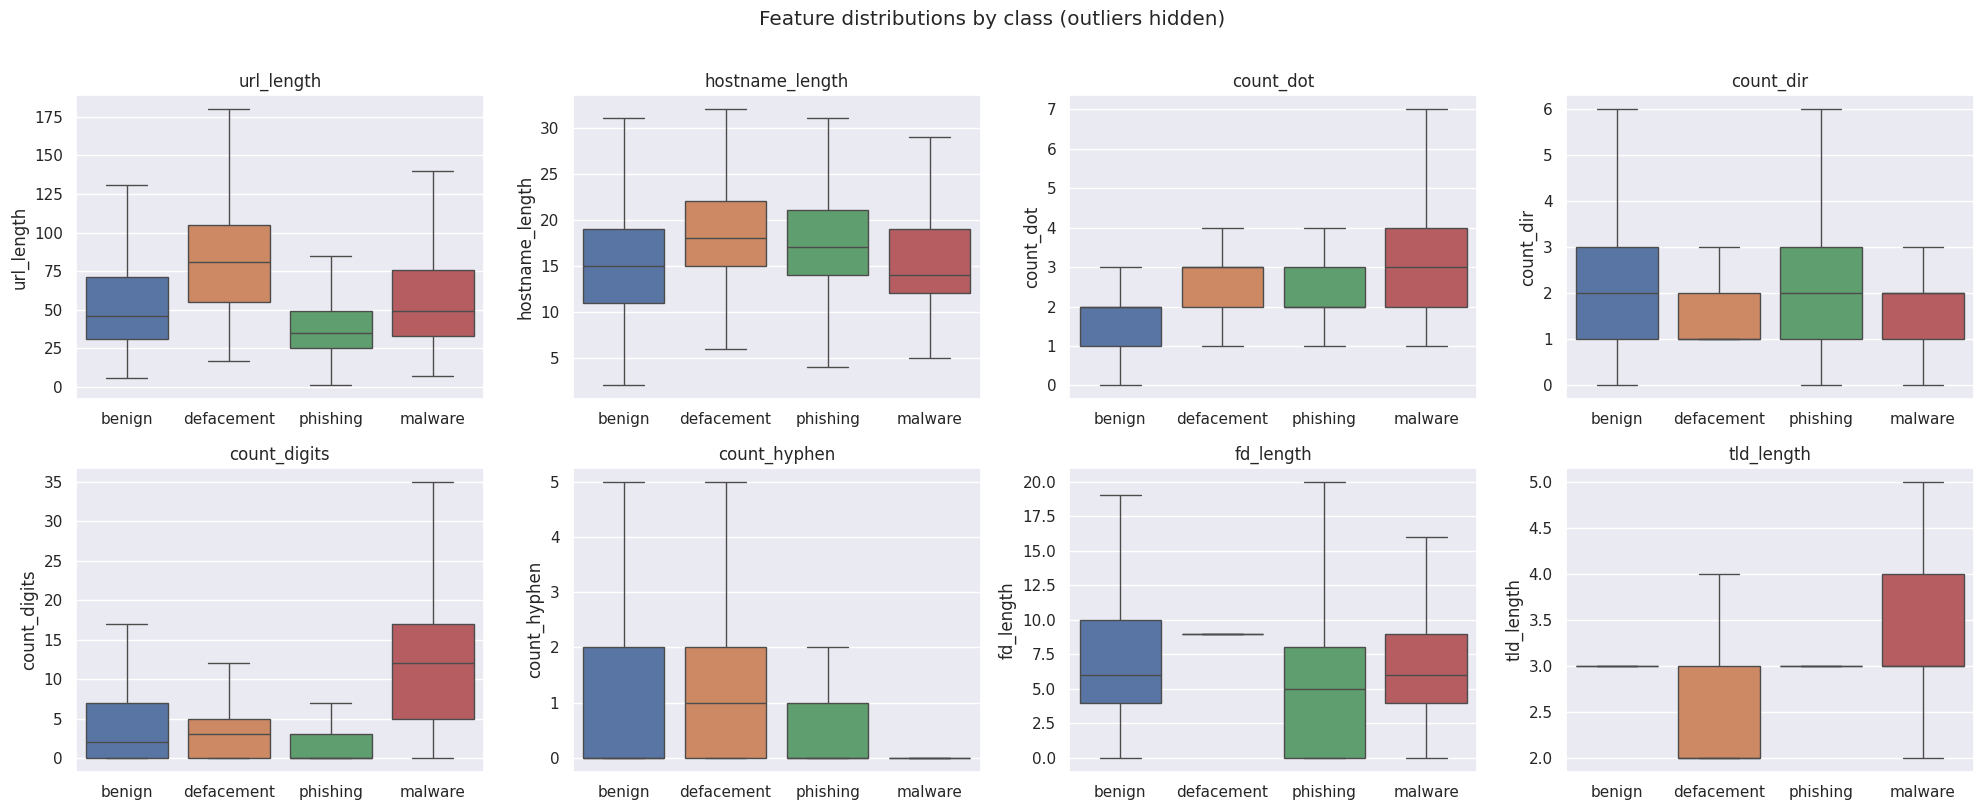

In [9]:
plot_feats = ["url_length","hostname_length","count_dot","count_dir","count_digits","count_hyphen","fd_length","tld_length"]
fig, axes = plt.subplots(2,4, figsize=(20,8))
for a,f in zip(axes.ravel(), plot_feats):
    sns.boxplot(data=FP, x="type", y=f, order=order, ax=a, showfliers=False, palette="deep")
    a.set_title(f); a.set_xlabel("")
plt.suptitle("Feature distributions by class (outliers hidden)", y=1.01); plt.tight_layout(); plt.show()

In [10]:
display(FP.groupby("type")[plot_feats+["count_percent","count_equal","count_question","count_at"]].median().reindex(order).T)

type,benign,defacement,phishing,malware
url_length,46.0,81.0,35.0,49.0
hostname_length,15.0,18.0,17.0,14.0
count_dot,2.0,3.0,2.0,3.0
count_dir,2.0,1.0,2.0,2.0
count_digits,2.0,3.0,0.0,12.0
count_hyphen,0.0,1.0,0.0,0.0
fd_length,6.0,9.0,5.0,6.0
tld_length,3.0,2.0,3.0,3.0
count_percent,0.0,0.0,0.0,0.0
count_equal,0.0,2.0,0.0,0.0


In [11]:
# Binary / rare flags: share of URLs where the flag is set, per class
flags = ["has_scheme","use_of_ip","short_url"]
rare  = (FP[["count_at","count_percent","count_embed_domain","count_www"]]>0).astype(int)
rate = pd.concat([FP[flags], rare.add_suffix(" > 0"), FP.type], axis=1).groupby("type").mean().reindex(order).T*100
display(rate.round(2).style.background_gradient(cmap="Blues", axis=1).format("{:.2f}%"))

type,benign,defacement,phishing,malware
has_scheme,8.26%,100.00%,26.41%,96.28%
use_of_ip,0.01%,0.00%,0.35%,36.19%
short_url,6.90%,2.70%,7.25%,2.17%
count_at > 0,0.14%,0.00%,0.73%,0.13%
count_percent > 0,4.63%,1.34%,1.41%,14.60%
count_embed_domain > 0,0.26%,0.00%,0.98%,0.48%
count_www > 0,4.02%,69.80%,40.41%,9.51%


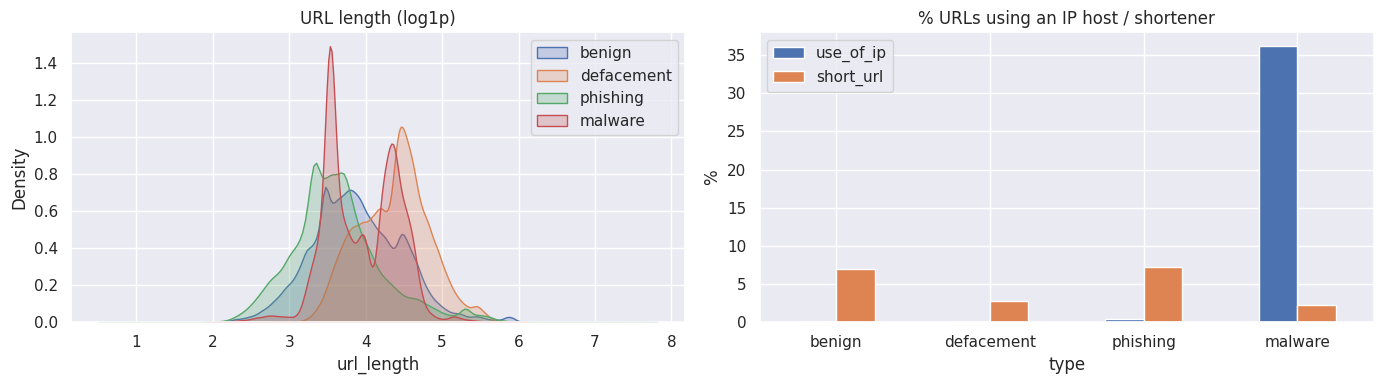

In [12]:
fig, ax = plt.subplots(1,2, figsize=(14,4))
for t in order:
    sns.kdeplot(np.log1p(FP[FP.type==t].url_length), ax=ax[0], label=t, fill=True, alpha=.25)
ax[0].set_title("URL length (log1p)"); ax[0].legend()
rate.loc[["use_of_ip","short_url"]].T.plot.bar(ax=ax[1]); ax[1].set_title("% URLs using an IP host / shortener"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

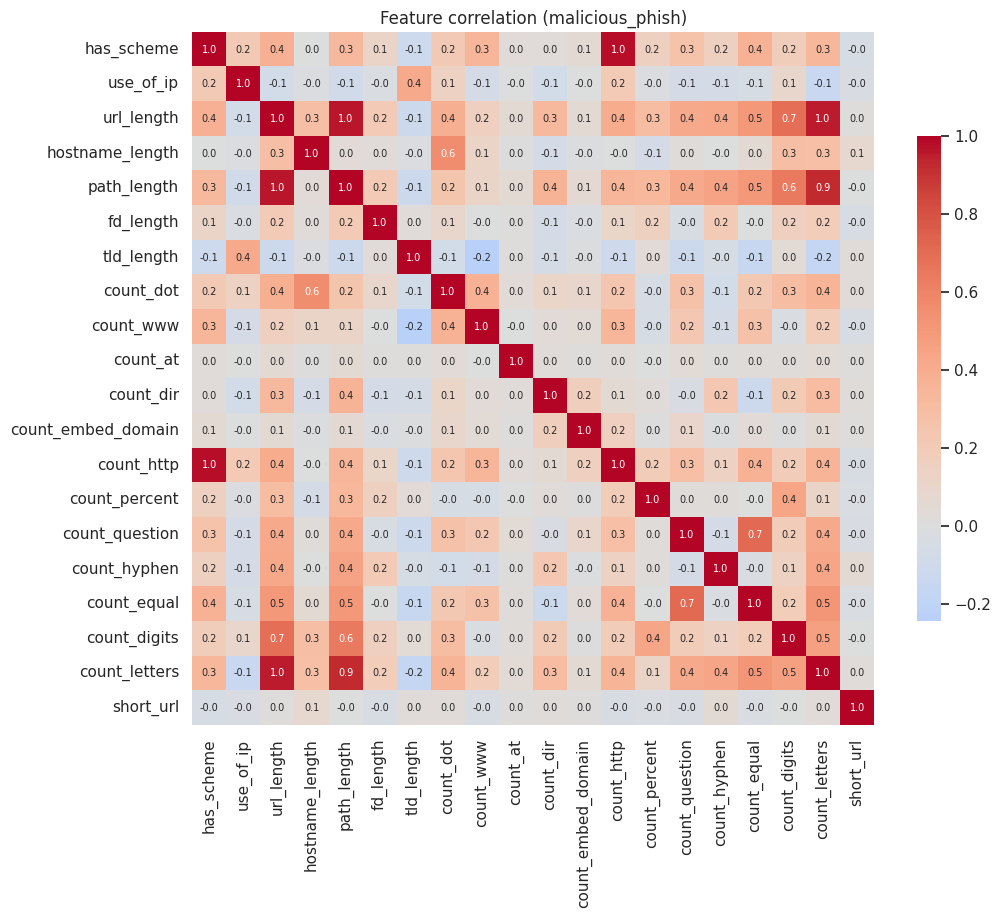

In [13]:
corr = FP.drop(columns="type").corr()
plt.figure(figsize=(11,9)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size":7}, cbar_kws={"shrink":.7})
plt.title("Feature correlation (malicious_phish)"); plt.show()

**What the distributions show**

- **Defacement** URLs are long, deep and query-heavy (`index.php?option=com_content&view=article&id=...`), so they separate easily from the other classes. This matches the 0.99 F1 in the paper.
- **Benign** URLs are short, with few digits and few query characters.
- **Phishing and malware** overlap heavily on these simple counts. This is why they are the hardest classes (malware F1 of 0.80 to 0.88 in the paper).
- Several count features are strongly correlated with `url_length` (digits, letters, dots). Tree models tolerate this, but it is worth remembering for feature selection.

**Paper claims worth re-checking.** Two statements in the paper do not seem to follow from our data and should be tested during modelling rather than repeated:

- *"Only malware URLs use IP addresses."* Check the `use_of_ip` rates above.
- *"The shorter the URL, the more authoritative; only benign and phishing have short URLs."*

## 6. Dataset bias: the URL scheme (`http://` / `https://`)

,malicious_phish: has scheme
type,
benign,8.3
defacement,100.0
phishing,26.4
malware,96.3


,balanced_urls: has scheme
label,
benign,100.0
malicious,77.7



balanced_urls, share starting with https://:
label
benign       100.0
malicious      6.3

balanced_urls, share starting with https://www.:
label
benign       99.8
malicious     0.5


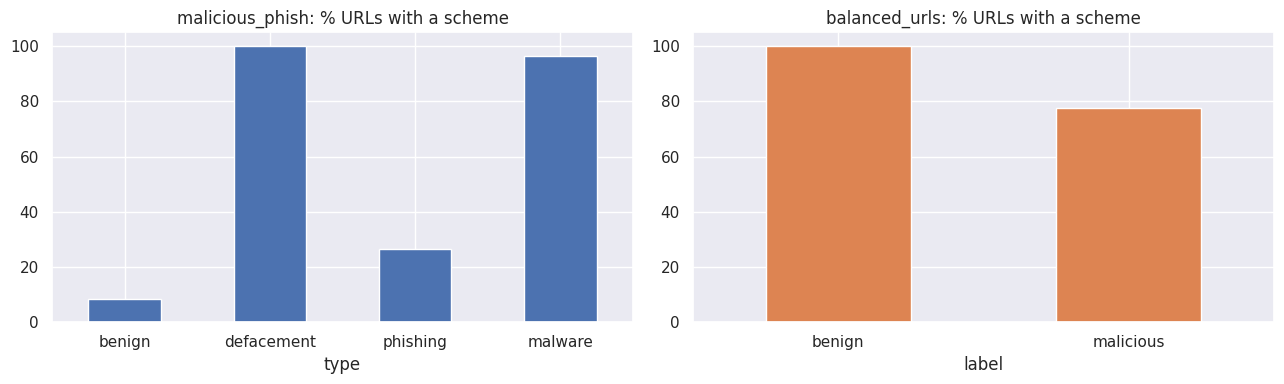

In [14]:
sch = pd.concat([
    FP.groupby("type").has_scheme.mean().reindex(order).rename("malicious_phish: has scheme"),
], axis=1)*100
sch2 = (FB.groupby("label").has_scheme.mean()*100).rename("balanced_urls: has scheme")
display(sch.round(1)); display(sch2.round(1).to_frame())

bal_https = bal.url.str.startswith("https://").groupby(bal.label).mean()*100
print("\nbalanced_urls, share starting with https://:"); print(bal_https.round(1).to_string())
print("\nbalanced_urls, share starting with https://www.:"); print((bal.url.str.startswith("https://www.").groupby(bal.label).mean()*100).round(1).to_string())

fig, ax = plt.subplots(1,2, figsize=(13,4))
sch["malicious_phish: has scheme"].plot.bar(ax=ax[0], color="C0"); ax[0].set_title("malicious_phish: % URLs with a scheme"); ax[0].tick_params(axis="x", rotation=0)
sch2.plot.bar(ax=ax[1], color="C1"); ax[1].set_title("balanced_urls: % URLs with a scheme"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Important finding.** Whether a URL has a scheme is almost a label in both files:

- In `malicious_phish.csv`, only about 8% of benign URLs have a scheme, against 100% of defacement and about 96% of malware. A model can score well just by checking for `http://`, which says little about how malicious a URL actually is.
- In `balanced_urls.csv`, about 99.99% of benign URLs begin with `https://` (mostly `https://www.`, the style of popular-site lists), while only about 78% of malicious ones have any scheme.

The same scheme-based shortcut therefore flatters accuracy in both datasets. For the modelling stage we plan to: (a) strip the scheme (and optionally `www.`) before feature extraction, and (b) report results both with and without scheme-related features, so we can say how much of the paper's 96.6% comes from this artefact.

## 7. Sample URLs per class (sanity check)

In [15]:
for t in order:
    print(f"--- {t} ---")
    for u in phish[phish.type==t].url.sample(4, random_state=3): print("  ", u[:110])

--- benign ---
   jigsaw.com/scid2053008/ph_d_david_l_rainey.xhtml?ver=5
   pipl.com/directory/name/Mair/Danny
   rbc.com/governance/executive-officers.html
   youtube.com/watch?v=DySZPfKo8co
--- defacement ---
   http://www.ekino-neureut.de/index.php?option=com_phocagallery&view=category&id=29:gottesdienst-im-gruenen-2012
   http://kerryshacklett.com/index.php?option=com_jevents&task=day.listevents&year=2013&month=01&day=26&Itemid=56
   http://www.khd.at/index.php?option=com_rsgallery2&page=inline&id=133&Itemid=7
   http://www.goldec.ch/index.php?option=com_content&view=article&id=20:banentreprise01&catid=21:entreprise&Itemi
--- phishing ---
   feu7654te.isa-geek.org
   eaglestar.net/Land_Buyers_List/index.html
   canningwalker.com
   games.groups.yahoo.com/group/kindredhavenofthenight/
--- malware ---
   http://www.114633.com/app/member/SportOption.php?uid=guest&langx=gb
   imprimamais.com/joomla/cache/media/gate.php
   http://121.180.75.151:19218/.i
   http://9779.info/%E5%85%B3%E4%

## 8. Summary

In [16]:
n_dup = phish.duplicated().sum()
print(f'''
DATASET SUMMARY
- malicious_phish.csv : {len(phish):,} URLs, 2 columns (url, type), 4 classes, 0 nulls
- balanced_urls.csv   : {len(bal):,} URLs, 3 columns (url, label, result), 2 classes (50/50), 0 nulls, 0 duplicates
- Class counts in malicious_phish match the paper (Fig. 7) exactly.
- {n_dup:,} exact duplicate rows ({n_dup/len(phish):.2%}) and {len(conflict)} URLs with conflicting labels in malicious_phish.
- {len(set_p&set_b):,} URLs overlap between the two files (do not mix them across train/test).
- Imbalanced 4-class data (malware = {(phish.type=="malware").mean():.1%}); the scheme feature is a near-perfect shortcut.

NEXT STEPS
1. Drop exact duplicates; resolve the conflicting-label URLs.
2. Strip scheme/www before feature extraction (and report with/without).
3. Stratified 80/20 split; Random Forest, LightGBM, XGBoost as in the paper.
4. Report per-class precision/recall/F1, macro-F1 and confusion matrices (accuracy alone hides the malware weakness).
''')


DATASET SUMMARY
- malicious_phish.csv : 651,191 URLs, 2 columns (url, type), 4 classes, 0 nulls
- balanced_urls.csv   : 632,508 URLs, 3 columns (url, label, result), 2 classes (50/50), 0 nulls, 0 duplicates
- Class counts in malicious_phish match the paper (Fig. 7) exactly.
- 10,066 exact duplicate rows (1.55%) and 6 URLs with conflicting labels in malicious_phish.
- 210,817 URLs overlap between the two files (do not mix them across train/test).
- Imbalanced 4-class data (malware = 5.0%); the scheme feature is a near-perfect shortcut.

NEXT STEPS
1. Drop exact duplicates; resolve the conflicting-label URLs.
2. Strip scheme/www before feature extraction (and report with/without).
3. Stratified 80/20 split; Random Forest, LightGBM, XGBoost as in the paper.
4. Report per-class precision/recall/F1, macro-F1 and confusion matrices (accuracy alone hides the malware weakness).

